In [1]:
import pandas as pd
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (mean_absolute_error, r2_score, accuracy_score, confusion_matrix)

df = pd.read_csv("week10_students.csv")
df.head

<bound method NDFrame.head of     student_id                     name gender               program  \
0      AUCA001              Aline Uwase      F   Information Systems   
1      AUCA002          Eric Iradukunda      M  Software Engineering   
2      AUCA003        Diane Uwizeyimana      F            Networking   
3      AUCA004       Jean Bosco Ikirezi      M            Accounting   
4      AUCA005         Patrick Ingabire      M   Information Systems   
..         ...                      ...    ...                   ...   
145    AUCA146           Celestin Cyusa      M  Software Engineering   
146    AUCA147     Jeanette Mukeshimana      F            Networking   
147    AUCA148  Deogratias Mbarushimana      M            Accounting   
148    AUCA149       Fidele Ndagijimana      M   Information Systems   
149    AUCA150         Liliane Habimana      F  Software Engineering   

      district  attendance_pct  quiz_avg  assignments_avg  score  
0       Gasabo              55      31

In [2]:
#Exercise 1.1
print("Shape:", df.shape)

feature = ["quiz_avg", "assignments_avg", "attendance_pct"]
print(df[feature + ["score"]].corr()["score"].drop("score"))
# quiz_avg looks the most useful: its correlation with score (0.80) is the
# highest, clearly ahead of assignments_avg (0.54) and attendance_pct (0.24).

Shape: (150, 9)
quiz_avg           0.800726
assignments_avg    0.535983
attendance_pct     0.238118
Name: score, dtype: float64


In [3]:
#Exercise 1.2
X = df[feature]
y = df["score"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 42)
print("Train:", len(X_train), "Test:", len(X_test))

# We hide 25% of the students so we can test the model on data it has never
# seen. Scoring it on the students it learned from would be like marking a
# student on the exact questions they memorised: it would look great but tell
# us nothing about how it handles new students.

Train: 112 Test: 38


In [4]:
#Exercise 2.1
model = LinearRegression()
model.fit(X_train,y_train)
for name, coef in zip(feature, model.coef_):
    print(f"{name:16s} {coef:.3f}")
print("Intercept:", round(model.intercept_, 3))

quiz_avg         0.579
assignments_avg  0.365
attendance_pct   0.113
Intercept: -4.428


In [5]:
#Exercise 2.2
pred = model.predict(X_test)
mae = mean_absolute_error(y_test, pred)
r2 = r2_score(y_test, pred)
print("MAE:", round(mae, 2), "R2:", round(r2, 2))
# MAE 3.3: on average, the prediction is off by about 3 marks out of 100.
# For a dean: "if the model says 60, the real score is typically 57-63."
# R2 0.89: the model explains about 89% of why students' scores differ;
# the remaining 11% is things it cannot see (effort, illness, luck...).

MAE: 3.33 R2: 0.89


In [6]:
#Exercise 2.3
new = pd.DataFrame({"quiz_avg": [70], "assignments_avg": [75], "attendance_pct": [90]})
print("New student:", round(model.predict(new)[0], 1))

me = pd.DataFrame({"quiz_avg": [68], "assignments_avg": [84], "attendance_pct": [75]})
print("Me:", round(model.predict(me)[0], 1))

New student: 73.7
Me: 74.1


In [7]:
#Exercise 3.1
df["passed"] = (df["score"] >= 50).astype(int)
print(df["passed"].value_counts())
Xc_train, Xc_test, yc_train, yc_test = train_test_split(X, df["passed"], test_size=0.25, random_state=42)

clf = LogisticRegression(max_iter=1000)
clf.fit(Xc_train, yc_train)

passed
1    131
0     19
Name: count, dtype: int64


,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [8]:
#Exercise 3.2
cpred = clf.predict(Xc_test)
print("Model accuracy:", round(accuracy_score(yc_test, cpred), 3))
print("Lazy baseline: ", round(yc_test.mean(), 3))
print(confusion_matrix(yc_test, cpred))
#the lazy baseline catches 0 of the 4 failing students, while our model correctly flags 3 of 4
# the accuracies are the same so statement "Everyone passes" is true 89.5% of the time.

Model accuracy: 0.895
Lazy baseline:  0.895
[[ 3  1]
 [ 3 31]]


In [11]:
#Exercise 4.1
def test_r2(features_df):
    a, b, c, d = train_test_split(features_df, y, test_size=0.25, random_state=42)
    m = LinearRegression().fit(a, c)
    return r2_score(d, m.predict(b))
    
r2_quiz = test_r2(df[["quiz_avg"]])
r2_three = test_r2(df[feature])
r2_prog = test_r2(pd.get_dummies(df[feature + ["program"]],columns=["program"], drop_first=True))
print(pd.DataFrame({"Model": ["1. quiz only", "2. three features", "3. three + program"],"R2": [r2_quiz, r2_three, r2_prog]}).round(3))

# Going from quiz only to all three numeric features helped a lot (0.62 -> 0.89):
# assignments and attendance carry real extra information.
# Adding program did NOT help (0.89 -> 0.88): the program says little the other
# scores don't already tell us, and extra columns can add noise on a small
# dataset (only 112 training rows). Lesson: more features are not automatically
# better - add information that is new and relevant, and always test on unseen data.

                Model     R2
0        1. quiz only  0.624
1   2. three features  0.887
2  3. three + program  0.880


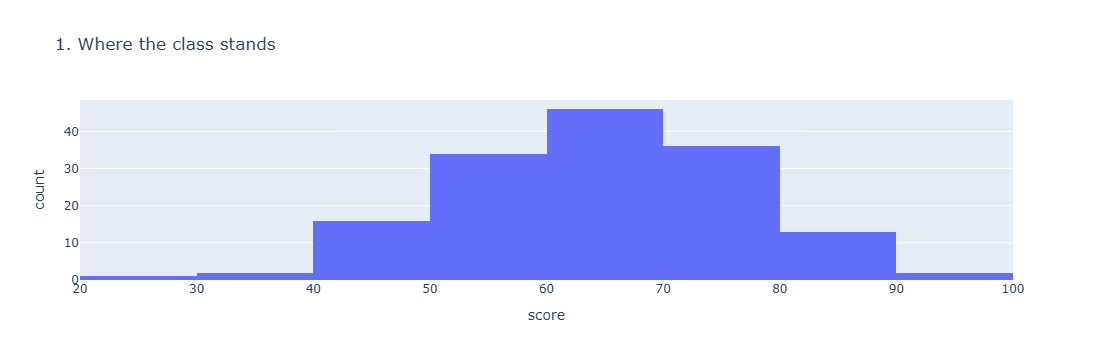

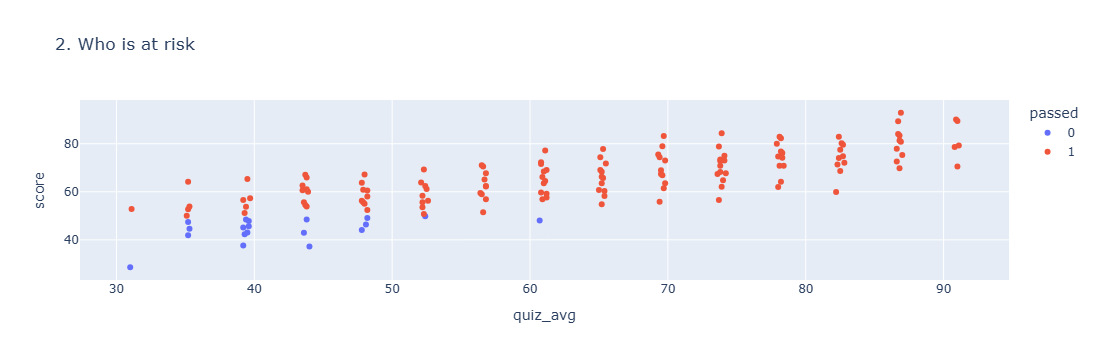

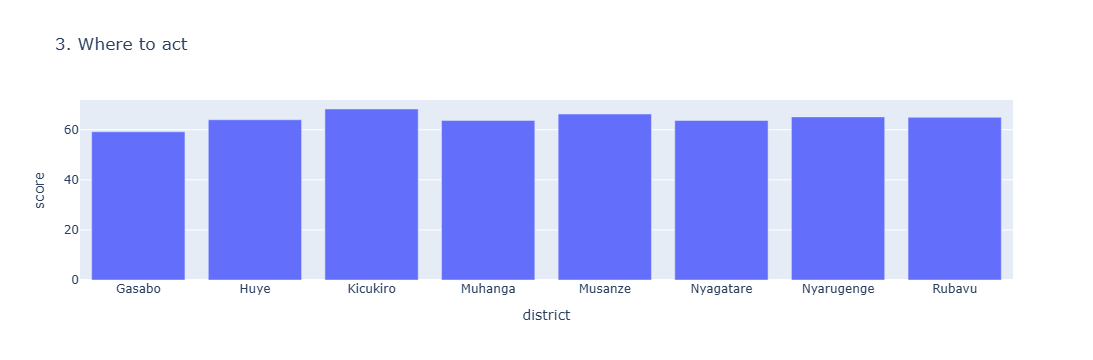

In [12]:
#Exercise 5.1
fig1 = px.histogram(df, x="score", nbins=12, title="1. Where the class stands")
fig1.show()
df["passed"] = df["passed"].astype(str)
fig2 = px.scatter(df, x="quiz_avg", y="score", color="passed",hover_name="name", title="2. Who is at risk")
fig2.show()
avg = df.groupby("district")["score"].mean().reset_index()
fig3 = px.bar(avg, x="district", y="score", title="3. Where to act")
fig3.show()

In [13]:
#Exercise 5.2
fig2.write_html("class_dashboard.html")

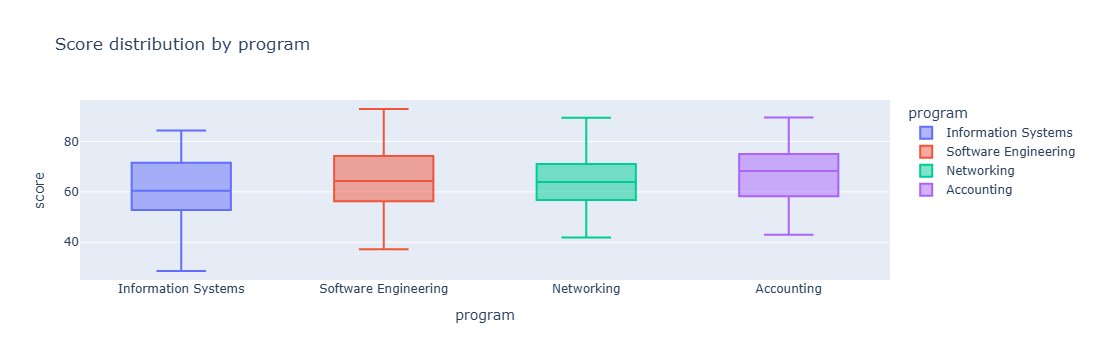

In [14]:
#Bonus
fig4 = px.box(df, x="program", y="score", color="program",title="Score distribution by program")
fig4.show()